# Making the model smaller and faster (no retraining)

We take the trained model and change **how it is stored and run**, then measure
what each change gains (file size, speed) and what it costs (accuracy).

| Variant | What changes |
|---|---|
| **PyTorch FP32** | The trained model as it is. This is the "before". |
| **ONNX FP32** | Same weights, saved in a format made for running predictions, not training. |
| **OpenVINO FP32** | Same weights, run by Intel's runtime, which is tuned for CPUs. |
| **OpenVINO INT8** | Weights and activations stored as 8-bit integers instead of 32-bit floats. |
| **INT8 at 800 / 640 px** | The INT8 model fed smaller pages: fewer pixels, less work. |

Everything runs on **CPU**, because a demo app or a small server usually has no GPU.
Every variant is scored on the same **500 validation pages**.

## 1. Install

In [1]:
# CPU-only PyTorch is much smaller to download. Skip these lines if already installed.
%pip install -q torch torchvision --index-url https://download.pytorch.org/whl/cpu
%pip install -q "ultralytics==8.3.221" onnx onnxslim onnxruntime openvino nncf pandas matplotlib


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: /tmp/claude-1000/-home-beka-Desktop-upgaming/59862bc9-579f-431c-8f56-ad3d55c070c7/scratchpad/venv/bin/python3 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: /tmp/claude-1000/-home-beka-Desktop-upgaming/59862bc9-579f-431c-8f56-ad3d55c070c7/scratchpad/venv/bin/python3 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 2. Settings

In [2]:
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from ultralytics import YOLO

MODEL = Path("../models/best_1024_60ep.pt")
PAGES = Path("../data/validation_pages").resolve()  # images/ and labels/
OUTPUT = Path("../results/05_optimization")
TIMED_PAGES = 50  # Pages used to measure speed.

OUTPUT.mkdir(exist_ok=True)

# Work on a copy, so the exported files land in OUTPUT and not next to the original.
model_copy = OUTPUT / "model.pt"
shutil.copy2(MODEL, model_copy)

# Dataset config for scoring. "train" is only needed because Ultralytics requires the key.
data_config = OUTPUT / "data.yaml"
data_config.write_text(yaml.safe_dump({
    "path": str(PAGES),
    "train": "images",
    "val": "images",
    "names": {0: "table"},
}))

pages = sorted((PAGES / "images").glob("*.png"))
print(f"Model: {MODEL} | validation pages: {len(pages)}")

Model: ../models/best_1024_60ep.pt | validation pages: 500


## 3. The variants

Each row: a name, the export format (`None` = keep PyTorch), the input size, and
whether to use INT8.

**About INT8 calibration.** To turn 32-bit floats into 8-bit integers, the
exporter needs to know the usual range of values inside the network. It runs a
few hundred pages through the model to measure this. It only looks at the
images, never at the labels, so nothing is learned. Ultralytics uses the `val`
pages for this by default; the only pages we have locally are the validation
pages, so we use those.

In [3]:
VARIANTS = [
    # name,                  format,     imgsz, int8
    ("PyTorch FP32",          None,       1024,  False),
    ("ONNX FP32",             "onnx",     1024,  False),
    ("OpenVINO FP32",         "openvino", 1024,  False),
    ("OpenVINO INT8",         "openvino", 1024,  True),
    ("OpenVINO INT8, 800 px", "openvino", 800,   True),
    ("OpenVINO INT8, 640 px", "openvino", 640,   True),
]

## 4. Helper functions

In [4]:
def export(name, export_format, imgsz, int8):
    # Export the model, then move the result to a name of its own,
    # because Ultralytics always uses the same output name for a format.
    exported = Path(YOLO(model_copy).export(
        format=export_format, imgsz=imgsz, int8=int8, data=str(data_config), device="cpu",
    ))
    suffix = ".onnx" if export_format == "onnx" else "_openvino_model"
    target = OUTPUT / (name.lower().replace(",", "").replace(" ", "_") + suffix)
    if target.is_dir():
        shutil.rmtree(target)
    shutil.move(exported, target)
    return target


def size_mb(path):
    # OpenVINO saves a folder; add up all its files.
    files = [path] if path.is_file() else list(path.rglob("*"))
    return sum(f.stat().st_size for f in files if f.is_file()) / 1e6


def score(model, imgsz):
    metrics = model.val(
        data=str(data_config), imgsz=imgsz, batch=1, device="cpu",
        half=False, rect=False, conf=0.001, plots=False, verbose=False,
    )
    return float(metrics.box.map50), float(metrics.box.map)


def ms_per_page(model, imgsz):
    # Time one page at a time, like an app answering one request.
    # Includes resizing the page and removing overlapping boxes, not just the network.
    for page in pages[:5]:  # Warm-up: the first calls are always slower.
        model.predict(page, imgsz=imgsz, device="cpu", verbose=False)

    times = []
    for page in pages[:TIMED_PAGES]:
        start = time.perf_counter()
        model.predict(page, imgsz=imgsz, device="cpu", verbose=False)
        times.append(time.perf_counter() - start)
    return 1000 * np.median(times)

## 5. Export, score and time every variant

Takes about 15–30 minutes on a laptop CPU. INT8 exports are the slowest step.

In [5]:
rows = []
for name, export_format, imgsz, int8 in VARIANTS:
    print(f"\n===== {name} =====")
    path = model_copy if export_format is None else export(name, export_format, imgsz, int8)
    model = YOLO(str(path), task="detect")

    map50, map50_95 = score(model, imgsz)
    rows.append({
        "variant": name,
        "size MB": round(size_mb(path), 1),
        "ms per page": round(ms_per_page(model, imgsz), 1),
        "mAP50": round(map50, 4),
        "mAP50-95": round(map50_95, 4),
    })
    print(rows[-1])

results = pd.DataFrame(rows).set_index("variant")
results.to_csv(OUTPUT / "optimization_results.csv")


===== PyTorch FP32 =====


Ultralytics 8.3.221 🚀 Python-3.11.6 torch-2.14.1+cpu CPU (12th Gen Intel Core i7-12700H)


YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2728.9±1683.8 MB/s, size: 331.8 KB)



val: Scanning /home/beka/Desktop/upgaming/table-detection/data/validation_pages/labels.cache... 500 images, 382 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 500/500 69.9Mit/s 0.0s

...

                   all        500        180      0.895      0.808      0.867      0.785


Speed: 1.2ms preprocess, 27.5ms inference, 0.0ms loss, 1.4ms postprocess per image


Loading ../results/05_optimization/openvino_int8_640_px_openvino_model for OpenVINO inference...


Using OpenVINO LATENCY mode for batch=1 inference on CPU...


{'variant': 'OpenVINO INT8, 640 px', 'size MB': 3.4, 'ms per page': np.float64(61.1), 'mAP50': 0.8671, 'mAP50-95': 0.7849}


## 6. Results

In [6]:
baseline = results.iloc[0]
results["smaller"] = (baseline["size MB"] / results["size MB"]).round(1).astype(str) + "x"
results["faster"] = (baseline["ms per page"] / results["ms per page"]).round(1).astype(str) + "x"
results["mAP50-95 change"] = (results["mAP50-95"] - baseline["mAP50-95"]).round(4)
results

,size MB,ms per page,mAP50,mAP50-95,smaller,faster,mAP50-95 change
variant,,,,,,,
PyTorch FP32,5.6,373.1,0.8943,0.8090,1.0x,1.0x,0.0000
ONNX FP32,10.9,251.3,0.8943,0.8090,0.5x,1.5x,0.0000
OpenVINO FP32,10.9,159.1,0.8943,0.8090,0.5x,2.3x,0.0000
OpenVINO INT8,3.5,96.1,0.8937,0.8028,1.6x,3.9x,-0.0062
"OpenVINO INT8, 800 px",3.4,73.0,0.8928,0.8038,1.6x,5.1x,-0.0052
"OpenVINO INT8, 640 px",3.4,61.1,0.8671,0.7849,1.6x,6.1x,-0.0241


### Speed vs. accuracy

Up and to the left is better: higher accuracy, less time per page.

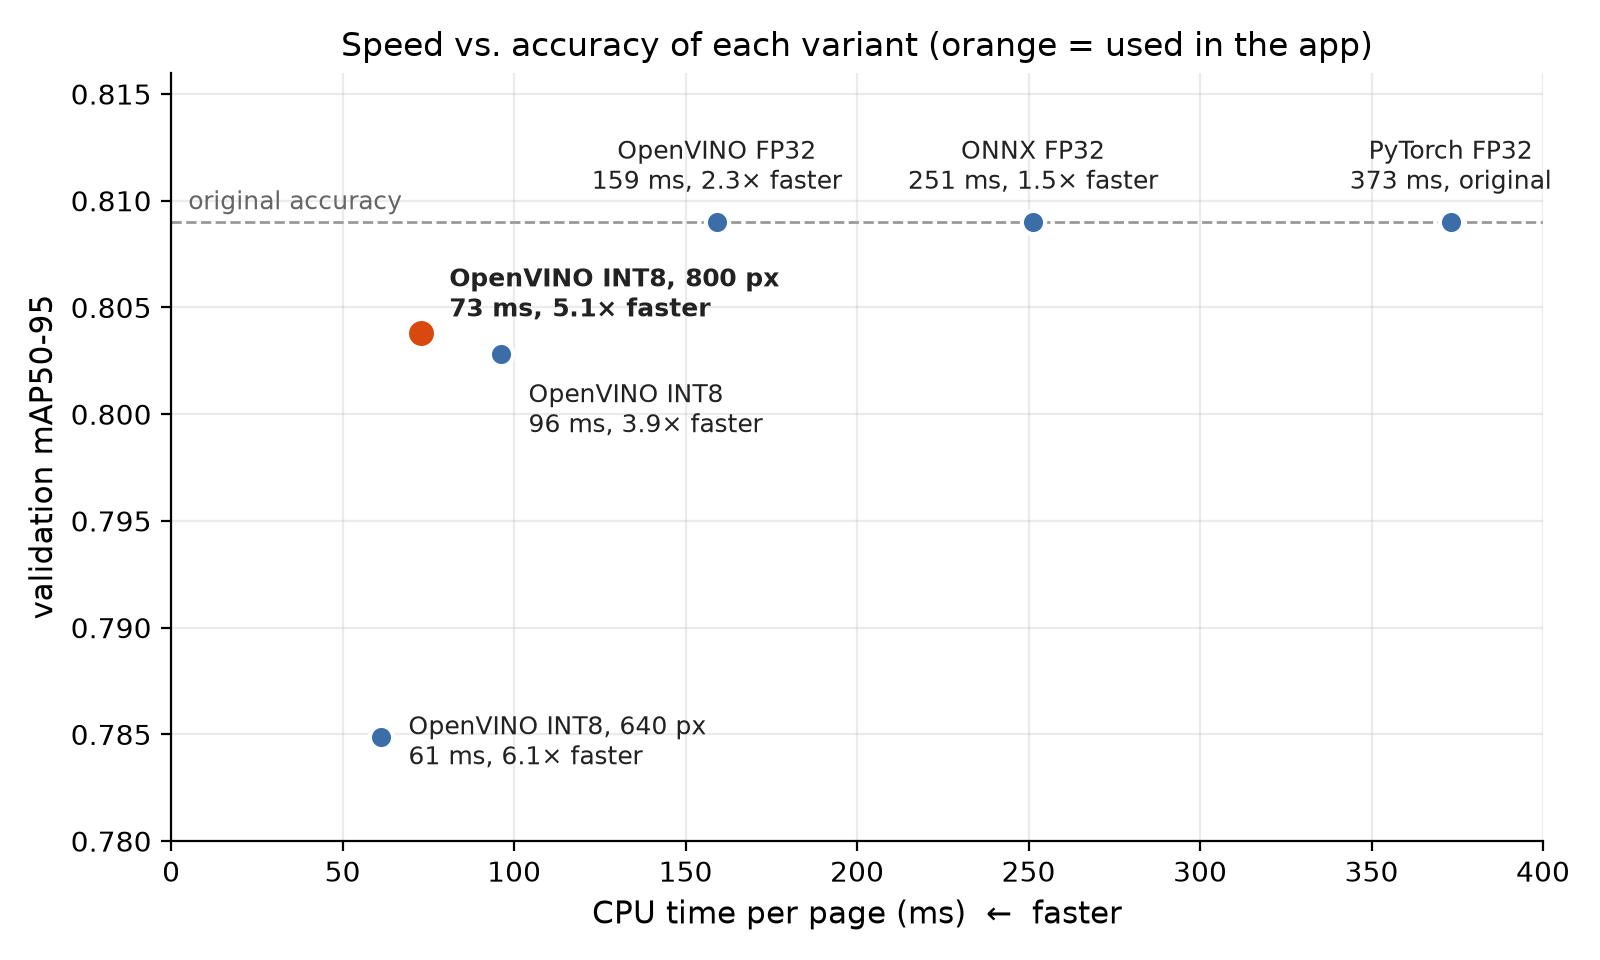

In [7]:
CHOSEN = "OpenVINO INT8, 800 px"
original = results.loc["PyTorch FP32"]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.axhline(original["mAP50-95"], color="#999999", linewidth=1, linestyle="--", zorder=1)
ax.text(5, original["mAP50-95"] + 0.0006, "original accuracy", color="#666666", fontsize=9)

# Where each label goes, relative to its point (in points), so no labels overlap.
LABEL_OFFSETS = {
    "PyTorch FP32": (0, 12),
    "ONNX FP32": (0, 12),
    "OpenVINO FP32": (0, 12),
    "OpenVINO INT8": (10, -28),
    "OpenVINO INT8, 800 px": (10, 6),
    "OpenVINO INT8, 640 px": (10, -10),
}

for name, row in results.iterrows():
    chosen = name == CHOSEN
    ax.scatter(row["ms per page"], row["mAP50-95"], s=110 if chosen else 70, zorder=3,
               color="#D9480F" if chosen else "#3B6EA8", edgecolor="white", linewidth=1.5)
    speedup = original["ms per page"] / row["ms per page"]
    timing = "original" if name == "PyTorch FP32" else f"{speedup:.1f}× faster"
    label = f"{name}\n{row['ms per page']:.0f} ms, {timing}"
    offset = LABEL_OFFSETS[name]
    ax.annotate(label, (row["ms per page"], row["mAP50-95"]), textcoords="offset points",
                xytext=offset, ha="center" if offset[0] == 0 else "left",
                fontsize=9, fontweight="bold" if chosen else "normal", color="#222222")

ax.set_xlim(0, 400)
ax.set_ylim(0.780, 0.816)
ax.set_xlabel("CPU time per page (ms)  ←  faster", fontsize=11)
ax.set_ylabel("validation mAP50-95", fontsize=11)
ax.set_title("Speed vs. accuracy of each variant (orange = used in the app)", fontsize=12)
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUTPUT / "speed_vs_accuracy.png", dpi=300)
plt.show()